# `ar_digithead_target` on S7_k02345, seed 42 (notebook 35c)

This is the ORIGINAL Transformer AR (pos(t) kept) with target-cell coordinates in the output part and the output changed:
* **10-way digit head** (initialized from the original head's digit rows);
* **loss on the 36 answer digits only** (no EOS target);
* **36 decoding steps**; `<EOS>` is appended, not predicted.

Target coordinates: YES: each output-part position carries the (row, col) of the cell it predicts (<OUTPUT> -> (0,0), answer of cell j-1 -> cell j).

| model | pos(t) | head / loss | target coords | notebook |
|---|---|---|---|---|
| original AR | yes | 20-way, 36 + EOS | no | 23b |
| `ar_digithead` | yes | **10-way, 36** | no | 35a |
| `ar_slotpos_digithead` | no | **10-way, 36** | no | 35b |
| `ar_digithead_target` | yes | **10-way, 36** | **yes** | 35c |
| `ar_slotpos_digithead_target` | no | 10-way, 36 | yes | 34 (singletons 1.00, k=6 1.00, k=7 0.985) |

**Questions.** 35a: does removing the EOS target alone fix the original AR? 35b vs 34: are target coordinates still
needed once the EOS target is gone? 35c vs 34: does keeping pos(t) matter once both changes are made?

Run 35a and 35b at the same time. The last cell (rerun after both finish) shows the full comparison table.
**Send back `AR_Ablation_S7_k02345_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: d4f24e6ed31750a04c2e49503d9e3854ea2f2f25


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ["S7_k02345"]
RUN_MODELS = ["ar_digithead_target"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"                # same folder as notebooks 23 / 27 / 29 (model subfolders differ)
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX, ar_ablation as AB
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [3]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation (resumable) ---------------------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                      subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
display(status)


[S7_k02345] S=7 train k=[0, 2, 3, 4, 5] | val 1500 | manifests bdf24c327a65

=== S7_k02345 / ar_digithead_target ===
  microbatch probe: 256 fits
[ar_digithead_target] 10,699,786 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.6079 (best) | subset(160) exact 0.163 cell 0.363
  step 500/20000 loss 1.2479 lr 3.00e-04 | 24.30 steps/s, 6221 ex/s | ETA 13.4 min
  [val @ 500] cell CE 1.2364 (best) | subset(160) exact 0.200 cell 0.380
  [val @ 750] cell CE 1.1234 (best) | subset(160) exact 0.206 cell 0.397
  step 975/20000 loss 0.9676 lr 2.99e-04 | 23.97 steps/s, 6137 ex/s | ETA 13.2 min
  [val @ 1000] cell CE 0.9987 (best) | subset(160) exact 0.219 cell 0.427
  [val @ 1250] cell CE 0.7509 (best) | subset(160) exact 0.231 cell 0.537
  step 1475/20000 loss 0.4647 lr 2.97e-04 | 23.99 steps/s, 6140 ex/s | ETA 12.9 min
  [val @ 1500] cell CE 0.4088 (best) | subset(160) exact 0.369 cell 0.698
  [val @ 1750] c

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02345,ar_digithead_target,True,True,82000,20000,True


# Transformer AR ablations on S7_k02345 (seed 42, LAST checkpoint, 20,000 updates)
Trained k = 0,2,3,4,5 in 7 slots; held out: singletons (k=1) at every slot, k=6, k=7. References: query AR (29b) and causal encoder (23b).


### Availability


,model,label,status
0,transformer_ar,original AR,ok
1,ar_slotpos,AR − pos(t),ok
2,ar_digiteos,AR + 11-way head (digits+EOS),ok
3,ar_slotpos_digiteos,AR − pos(t) + 11-way head,ok
4,ar_slotpos_digiteos_target,AR − pos(t) + 11-way head + target coords,ok
5,ar_digithead,AR + 10-way head (36 digits),ok
6,ar_slotpos_digithead,AR − pos(t) + 10-way head (36 digits),ok
7,ar_digithead_target,AR + 10-way head (36 digits) + target coords,ok
8,ar_slotpos_digithead_target,AR − pos(t) + 10-way head (36 digits) + target...,ok
9,nexttoken_ar,"query AR, next-token feedback",no ARTIFACT



### 1. Exact accuracy by test k (k=1 = singletons over all slots)


model,k,role,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,AR − pos(t) + 11-way head + target coords,AR + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits),AR + 10-way head (36 digits) + target coords,AR − pos(t) + 10-way head (36 digits) + target coords,query AR,causal encoder
0,0,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,1,singleton,0.3305,0.0923,0.3491,0.3384,0.7526,0.5281,0.0000,0.2061,1.0000,1.0000,1.0000
2,2,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,3,trained,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,4,trained,1.0000,0.9998,1.0000,1.0000,0.9998,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,5,trained,1.0000,0.9996,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,6,+1 step,0.0136,0.0400,0.0023,0.2115,0.1163,0.0000,0.0000,0.0328,0.9996,1.0000,0.9495
7,7,+2 step,0.0024,0.1121,0.0009,0.0048,0.1073,0.0000,0.3462,0.0484,0.9848,0.9964,0.4642



### 2a. Singleton accuracy by operation


... (2 outputs left out)

model,op,slot,original AR,AR − pos(t),AR + 11-way head (digits+EOS),AR − pos(t) + 11-way head,AR − pos(t) + 11-way head + target coords,AR + 10-way head (36 digits),AR − pos(t) + 10-way head (36 digits),AR + 10-way head (36 digits) + target coords,AR − pos(t) + 10-way head (36 digits) + target coords,query AR,causal encoder
0,A,1,0.000,0.601,0.000,0.000,0.144,0.000,0.0,0.000,1.0,1.0,1.0
1,A,2,0.000,0.106,0.000,0.000,0.230,0.058,0.0,0.000,1.0,1.0,1.0
2,A,3,0.000,0.165,0.000,0.000,0.628,0.048,0.0,0.000,1.0,1.0,1.0
3,A,4,0.000,0.029,0.000,0.000,0.990,1.000,0.0,0.000,1.0,1.0,1.0
4,A,5,0.000,0.025,0.000,0.015,0.908,0.994,0.0,0.000,1.0,1.0,1.0
5,A,6,0.000,0.000,0.051,0.042,0.808,0.995,0.0,0.000,1.0,1.0,1.0
6,A,7,0.000,0.000,1.000,0.846,0.088,0.997,0.0,0.000,1.0,1.0,1.0
7,B,1,0.958,0.094,0.301,1.000,1.000,0.999,0.0,0.711,1.0,1.0,1.0
8,B,2,0.984,0.094,0.993,1.000,1.000,1.000,0.0,0.630,1.0,1.0,1.0
9,B,3,0.999,0.094,1.000,1.000,1.000,1.000,0.0,0.766,1.0,1.0,1.0



### 3. k=6 failures that equal the word with ONE operation dropped (counts; 'drop #i' = i-th operation) (first 10 of 11 rows; full table in CSV export)


,model,k=6 records,failed,invalid outputs,drop #1,drop #2,drop #3,drop #4,drop #5,drop #6,drop some op / failed
0,original AR,20000,19729,0,1102,1003,1514,4310,12512,4404,0.634
1,AR − pos(t),20000,19201,4,1533,2500,4079,6374,3794,1621,0.484
2,AR + 11-way head (digits+EOS),20000,19954,0,966,931,1295,3576,9836,3909,0.493
3,AR − pos(t) + 11-way head,20000,15770,0,379,433,974,2217,3017,1752,0.198
4,AR − pos(t) + 11-way head + target coords,20000,17674,1,1180,2594,5357,4419,2299,1337,0.407
5,AR + 10-way head (36 digits),20000,20000,0,437,318,308,1110,3967,1981,0.198
6,AR − pos(t) + 10-way head (36 digits),20000,20000,0,2686,4534,5679,6141,4112,2372,0.638
7,AR + 10-way head (36 digits) + target coords,20000,19345,0,825,1436,3639,9065,4541,1904,0.476
8,AR − pos(t) + 10-way head (36 digits) + target...,20000,8,0,0,0,0,0,0,0,0.000
9,query AR,20000,1,0,0,0,0,0,0,0,0.000



### Accuracy vs test k


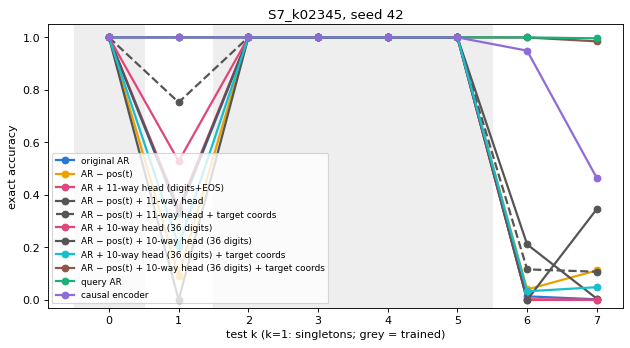

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/seed_42_ar_ablation/AR_Ablation_S7_k02345_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Comparison (reads saved predictions only; rerun after all runs finish) ---------------------------------------
rp = AB.report(RESULTS_ROOT, MODE, SEED)
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB and rp:
    from google.colab import files
    files.download(str(rp))
